In [1]:
# =============================================================================
# CELL 1 — IMPORTS, CONFIGURATION & REPRODUCIBILITY
# =============================================================================
import os
import random
import time

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import timm
from catboost import CatBoostClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    recall_score,
)

# ---------------------------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------------------------
_GLOBAL_SEED = 42

def seed_everything(seed: int = _GLOBAL_SEED) -> None:
    """Fix random seeds across all libraries for deterministic runs."""
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(_GLOBAL_SEED)

# ---------------------------------------------------------------------------
# Device selection
# ---------------------------------------------------------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🔥 Đang chạy hệ thống trên thiết bị: {DEVICE}")


🔥 Đang chạy hệ thống trên thiết bị: cuda


In [2]:
# =============================================================================
# CELL 2 — DATA LOADING & MERGE (Detection + Metadata)
# =============================================================================

# --- Constants for file paths ---
_DETECTION_CSV = "/kaggle/input/datasets/phanxunkhoa/mammovin/vindr_detection_v1_folds.csv"
_METADATA_CSV = "/kaggle/input/datasets/phanxunkhoa/mammovin/metadata.csv"

# --- Load raw tables ---
# low_memory=False silences mixed-dtype warnings on column 10
df_detection = pd.read_csv(_DETECTION_CSV, low_memory=False)
df_meta = pd.read_csv(_METADATA_CSV, low_memory=False)

# --- Normalise join keys ---
# Strip '.png' extension so image_id matches SOP Instance UID
df_detection["image_id_clean"] = df_detection["image_id"].str.replace(
    ".png", "", regex=False
)

# --- Inner join on clean image ID ---
df_combined = pd.merge(
    df_detection,
    df_meta,
    left_on="image_id_clean",
    right_on="SOP Instance UID",
    how="inner",
)

# --- Deduplicate & inspect ---
df_combined = df_combined.drop_duplicates(subset=["image_id"]).reset_index(drop=True)

print(f"📊 Kích thước tập dữ liệu tích hợp: {df_combined.shape}")
print("\n✨ Các cột thông tin có được sau khi kết hợp:")
print(list(df_combined.columns))


📊 Kích thước tập dữ liệu tích hợp: (20000, 55)

✨ Các cột thông tin có được sau khi kết hợp:
['patient_id', 'series_id', 'image_id', 'laterality', 'view', 'height', 'width', 'breast_birads', 'breast_density', 'finding_categories', 'finding_birads', 'xmin', 'ymin', 'xmax', 'ymax', 'split', 'resized_xmin', 'resized_ymin', 'resized_xmax', 'resized_ymax', 'fold', 'Architectural_Distortion', 'Asymmetry', 'Focal_Asymmetry', 'Global_Asymmetry', 'Mass', 'Nipple_Retraction', 'No_Finding', 'Skin_Retraction', 'Skin_Thickening', 'Suspicious_Calcification', 'Suspicious_Lymph_Node', 'density', 'image_id_clean', 'SOP Instance UID', 'Series Instance UID', 'SOP Instance UID.1', "Patient's Age", 'View Position', 'Image Laterality', 'Photometric Interpretation', 'Rows', 'Columns', 'Imager Pixel Spacing', 'Pixel Spacing', 'Pixel Padding Value', 'Pixel Padding Range Limit', 'Window Center', 'Window Width', 'Rescale Intercept', 'Rescale Slope', 'Rescale Type', 'Window Center & Width Explanation', 'Manufactu

In [3]:
# =============================================================================
# CELL 3 — MAMMOGRAPHY-SPECIFIC PREPROCESSING PIPELINE
# =============================================================================
# This is the SINGLE preprocessing path used for train / validation / test.
# 'augment=True' enables random flip + rotation; use only for training.
# =============================================================================

# --- Domain-specific constants (empirically estimated on VinDr-Mammo) ---
_MAMMO_IMG_SIZE = (1024, 1024)          # preserves microcalcifications
_MAMMO_MEAN = 0.2865                     # post-CLAHE channel mean
_MAMMO_STD = 0.1743                      # post-CLAHE channel std
_DEFAULT_CLAHE_CLIP = 2.0
_DEFAULT_CLAHE_TILE = (8, 8)
_DEFAULT_MEDIAN_KERNEL = 3
_MAX_ROTATION_DEG = 10.0


class AdvancedMammographyTransform:
    """Domain-specific mammography preprocessing.

    Steps (in order):
        1. Load grayscale DICOM-derived PNG.
        2. Resize to {_MAMMO_IMG_SIZE} via INTER_CUBIC.
        3. Median-filter to suppress device noise.
        4. CLAHE to amplify spiculated lesions.
        5. (train only) Random horizontal flip ± mild rotation.
        6. Normalise to [0, 1] → Z-score with VinDr-Mammo statistics.

    Args:
        clip_limit: CLAHE contrast clip limit.
        tile_grid_size: CLAHE tile grid dimensions.
        kernel_size: Median-filter kernel size (must be odd).
        augment: If True, apply random flip & rotation.
    """

    def __init__(
        self,
        clip_limit: float = _DEFAULT_CLAHE_CLIP,
        tile_grid_size: tuple = _DEFAULT_CLAHE_TILE,
        kernel_size: int = _DEFAULT_MEDIAN_KERNEL,
        augment: bool = False,
    ):
        self.clahe = cv2.createCLAHE(
            clipLimit=clip_limit, tileGridSize=tile_grid_size
        )
        self.kernel_size = kernel_size
        self.augment = augment
        self.mean = _MAMMO_MEAN
        self.std = _MAMMO_STD

    # ------------------------------------------------------------------
    # Public API
    # ------------------------------------------------------------------
    def __call__(self, img_path: str) -> torch.Tensor:
        img = self._load_and_resize(img_path)
        img = cv2.medianBlur(img, self.kernel_size)
        img = self.clahe.apply(img)

        if self.augment:
            img = self._apply_augmentation(img)

        return self._to_normalised_tensor(img)

    # ------------------------------------------------------------------
    # Internal helpers
    # ------------------------------------------------------------------
    @staticmethod
    def _load_and_resize(img_path: str) -> np.ndarray:
        """Load grayscale image → resize to target dimensions."""
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            # Graceful fallback: return a blank canvas on broken paths
            return np.zeros(_MAMMO_IMG_SIZE, dtype=np.uint8)

        if img.shape != _MAMMO_IMG_SIZE:
            img = cv2.resize(img, _MAMMO_IMG_SIZE, interpolation=cv2.INTER_CUBIC)
        return img

    @staticmethod
    def _apply_augmentation(img: np.ndarray) -> np.ndarray:
        """Random horizontal flip + small rotation (training only)."""
        if random.random() < 0.5:
            img = cv2.flip(img, 1)  # horizontal flip = mirror laterality

        angle = random.uniform(-_MAX_ROTATION_DEG, _MAX_ROTATION_DEG)
        h, w = img.shape
        rot_matrix = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
        img = cv2.warpAffine(
            img, rot_matrix, (w, h), borderMode=cv2.BORDER_REFLECT
        )
        return img

    def _to_normalised_tensor(self, img: np.ndarray) -> torch.Tensor:
        """Scale to [0, 1] → Z-score → add channel dim [1, H, W]."""
        img_tensor = torch.from_numpy(img.copy()).float() / 255.0
        img_tensor = (img_tensor - self.mean) / self.std
        return img_tensor.unsqueeze(0)


In [ ]:
# =============================================================================
# CELL 4 — LABEL ENCODING, FEATURE ENGINEERING & THREE-WAY SPLIT
# =============================================================================

# --- BI-RADS → integer-label mapping ----------------------------------------
# ĐÃ SỬA (vòng 6 — chuyển sang bài toán 3 LỚP GỘP): sau 6 cấu hình khác nhau
# ở tầng CatBoost (SMOTE x3 kiểu, class_weights thủ công, auto_class_weights=
# Balanced/SqrtBalanced) không cấu hình nào cho một điểm cân bằng chấp nhận
# được cho BI-RADS 3 (196-224 mẫu) — kết luận đây là giới hạn dữ liệu, không
# phải vấn đề hiệu chỉnh tham số. Gộp BI-RADS 2-3 (cùng dẫn tới hành động lâm
# sàng "theo dõi thêm") và BI-RADS 4-5 (cùng dẫn tới "cần sinh thiết/can
# thiệp") thành 2 nhóm lớn, đưa gần 1044 mẫu train vào nhóm "Benign-leaning"
# đủ lớn để học ranh giới ổn định, thay vì cố phân định ranh giới mờ nhạt
# giữa các nhãn thưa.
_BIRADS_TO_LABEL = {
    "BI-RADS 1": 0,   # Normal
    "BI-RADS 2": 1,   # Benign-leaning (gộp 2-3)
    "BI-RADS 3": 1,
    "BI-RADS 4": 2,   # Suspicious (gộp 4-5)
    "BI-RADS 5": 2,
}
_CLASS_NAMES_3 = ["Normal (BI-RADS 1)", "Benign-leaning (BI-RADS 2-3)", "Suspicious (BI-RADS 4-5)"]

# --- Breast-density → integer mapping ---------------------------------------
_DENSITY_MAPPING = {
    "DENSITY A": 0,
    "DENSITY B": 1,
    "DENSITY C": 2,
    "DENSITY D": 3,
}

# --- Three-way split constants (patient-grouped, leak-free) ------------------
#  • TRAIN_FOLDS              — train NN + CatBoost
#  • FEATURE_SELECTION_VAL    — feature-selection fitness + CatBoost early-stop
#  • TEST_FOLD                — held-out; touched once for the final report
TEST_FOLD = 0
FEATURE_SELECTION_VAL_FOLD = 1
# ĐÃ SỬA: dữ liệu thật (vindr_detection_v1_folds.csv) chỉ có 4 fold (0-3),
# KHÔNG có fold 4 — TRAIN_FOLDS=[2,3,4] cũ âm thầm chỉ dùng được fold 2,3
# (isin() không báo lỗi khi thiếu giá trị). Sửa đúng thực tế.
TRAIN_FOLDS = [2, 3]

# ---------------------------------------------------------------------------
# Build working dataframe
# ---------------------------------------------------------------------------
df = df_combined.copy()

# --- Label encoding ---
df["label"] = df["breast_birads"].map(_BIRADS_TO_LABEL)
df = df.dropna(subset=["label"])
df["label"] = df["label"].astype(int)

# --- Tabular feature: age ---
if "Patient's Age" in df.columns:
    df["age"] = (
        df["Patient's Age"]
        .str.replace("Y", "", regex=False)
        .astype(float)
    )
    df["age"] = df["age"].fillna(df["age"].median())

# --- Tabular feature: breast density ---
if "breast_density" in df.columns:
    df["density_code"] = (
        df["breast_density"]
        .map(_DENSITY_MAPPING)
        .fillna(2)
        .astype(int)
    )

# --- Fold assignment ---
# Prefer the OFFICIAL patient-grouped fold column shipped with VinDr-Mammo.
# Only fall back to a fresh GroupKFold if the official column is missing
# or invalid (ensures comparability with published benchmarks).
if "fold" not in df.columns or df["fold"].isna().any() or df["fold"].nunique() < 2:
    print("⚠️ Cột 'fold' chính thức bị thiếu/không hợp lệ — dùng GroupKFold dự phòng.")
    gkf = GroupKFold(n_splits=5)
    df["fold"] = -1
    for fold_idx, (_, val_idx) in enumerate(
        gkf.split(df, groups=df["patient_id"])
    ):
        df.loc[val_idx, "fold"] = fold_idx
else:
    print("✅ Sử dụng fold split chính thức (patient-grouped) từ VinDr-Mammo.")

# --- Summary ---
print(f"📊 Kích thước tập dữ liệu thật sau làm sạch: {df.shape}")
print("\n📊 Phân bổ nhãn theo từng fold:")
print(df.groupby("fold")["label"].value_counts().sort_index())

# ĐÃ THÊM: kiểm tra động — báo lỗi rõ ràng ngay nếu TEST_FOLD/FEATURE_SELECTION_VAL_FOLD/TRAIN_FOLDS tham chiếu fold không tồn tại
# trong dữ liệu thật (đúng loại lỗi vừa sửa ở trên với "fold 4").
_actual_folds = set(df["fold"].unique().tolist())
_referenced_folds = {TEST_FOLD, FEATURE_SELECTION_VAL_FOLD, *TRAIN_FOLDS}
_missing_folds = _referenced_folds - _actual_folds
if _missing_folds:
    raise ValueError(
        f"❌ TEST_FOLD/FEATURE_SELECTION_VAL_FOLD/TRAIN_FOLDS tham chiếu fold "
        f"{_missing_folds} KHÔNG TỒN TẠI trong dữ liệu thật (chỉ có {sorted(_actual_folds)})."
    )
print(f"✅ Xác nhận: TEST_FOLD={TEST_FOLD}, FEATURE_SELECTION_VAL_FOLD={FEATURE_SELECTION_VAL_FOLD}, TRAIN_FOLDS={TRAIN_FOLDS} — tất cả đều tồn tại trong {sorted(_actual_folds)}.")


In [5]:
# =============================================================================
# CELL 5 — DATASET CLASS & DATALOADER FACTORY
# =============================================================================

# --- Image-directory root ---
_IMAGE_DIR = (
    "/kaggle/input/datasets/shantanughosh/"
    "vindr-mammogram-dataset-dicom-to-png/images_png"
)

# --- Dataset ---
class VinDrMammoHighResDataset(Dataset):
    """PyTorch Dataset yielding (image, cat_features, cont_features, label)."""

    def __init__(self, dataframe: pd.DataFrame, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]

        img_tensor = self.transform(row["image_path"])

        cat_features = torch.tensor([row["density_code"]], dtype=torch.long)
        cont_features = torch.tensor([row["age"]], dtype=torch.float32)
        label = torch.tensor(row["label"], dtype=torch.long)

        return img_tensor, cat_features, cont_features, label


# --- Build image_path column (IMAGE_DIR / patient_id / image_id) -----------
def _build_image_path(row: pd.Series) -> str:
    """Join IMAGE_DIR, patient_id, and image_id into a full path."""
    return os.path.join(
        _IMAGE_DIR,
        str(row["patient_id"]),
        str(row["image_id"]),  # already ends with '.png'
    )


df["image_path"] = df.apply(_build_image_path, axis=1)

# --- Sanity-check the first path ---
sample_path = df.iloc[0]["image_path"]
print("📍 Đường dẫn mẫu sau khi cấu trúc lại:")
print(f"👉 {sample_path}")
file_ok = os.path.exists(sample_path)
print(f"\n🔍 Kết quả kiểm tra file tồn tại: {file_ok}")
if file_ok:
    print("✅ Tuyệt vời! Đường ống dẫn ảnh đã thông suốt hoàn toàn.")
else:
    print(
        "❌ Vẫn chưa tìm thấy! Bạn hãy chạy thử đoạn code quét `glob` "
        "ở bước trước để xem tầng thư mục cụ thể nhé."
    )

# --- Transforms & datasets --------------------------------------------------
train_transform = AdvancedMammographyTransform(augment=True)
eval_transform = AdvancedMammographyTransform(augment=False)

train_dataset = VinDrMammoHighResDataset(
    df[df["fold"].isin(TRAIN_FOLDS)], transform=train_transform
)
featsel_dataset = VinDrMammoHighResDataset(
    df[df["fold"] == FEATURE_SELECTION_VAL_FOLD], transform=eval_transform
)
test_dataset = VinDrMammoHighResDataset(
    df[df["fold"] == TEST_FOLD], transform=eval_transform
)

# --- DataLoaders ------------------------------------------------------------
# batch_size=8 is feasible because the backbone runs frozen (no_grad),
# saving GPU memory.
_BATCH_SIZE = 8
_NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=_BATCH_SIZE,
    shuffle=True,
    num_workers=_NUM_WORKERS,
    pin_memory=True,
)
featsel_loader = DataLoader(
    featsel_dataset,
    batch_size=_BATCH_SIZE,
    shuffle=False,
    num_workers=_NUM_WORKERS,
    pin_memory=True,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=_BATCH_SIZE,
    shuffle=False,
    num_workers=_NUM_WORKERS,
    pin_memory=True,
)

print("✅ Khởi tạo thành công bộ nạp dữ liệu thực tế!")
print(
    f"   ↳ Train: {len(train_dataset)} mẫu"
    f" | Feature-selection-val: {len(featsel_dataset)} mẫu"
    f" | Test (held-out): {len(test_dataset)} mẫu."
)


📍 Đường dẫn mẫu sau khi cấu trúc lại:
👉 /kaggle/input/datasets/shantanughosh/vindr-mammogram-dataset-dicom-to-png/images_png/<id>/<id>.png

🔍 Kết quả kiểm tra file tồn tại: True
✅ Tuyệt vời! Đường ống dẫn ảnh đã thông suốt hoàn toàn.
✅ Khởi tạo thành công bộ nạp dữ liệu thực tế!
   ↳ Train: 10000 mẫu | Feature-selection-val: 5000 mẫu | Test (held-out): 5000 mẫu.


In [6]:
# =============================================================================
# CELL 6 — FROZEN SWIN-V2 BACKBONE (pretrained feature extractor)
# =============================================================================

# ---------------------------------------------------------------------------
# Constants
# ---------------------------------------------------------------------------
_SWIN_MODEL_NAME = "swinv2_tiny_window16_256"
_SWIN_IMG_SIZE = (1024, 1024)         # matches _MAMMO_IMG_SIZE
_SWIN_OUT_CHANNELS = 768              # feature dim for SwinV2-Tiny
_SWIN_MAX_RETRIES = 3                 # download retries for HuggingFace Hub


class SpatialPreservingSwinBackbone(nn.Module):
    """Frozen SwinV2-Tiny backbone — high-res feature extraction.

    Runs the Swin Transformer with ``torch.no_grad()`` to save memory.
    Supports three loading strategies:
        - *pretrained* from HuggingFace Hub (default, with retries).
        - *local checkpoint* path (offline / competition rules).
        - *random init* (``pretrained=False``).

    Args:
        model_name: ``timm`` model identifier.
        pretrained: Download ImageNet-1k weights from the Hub.
        local_checkpoint_path: Path to a local ``state_dict`` (overrides Hub).
        max_retries: Number of download attempts before raising an error.
    """

    def __init__(
        self,
        model_name: str = _SWIN_MODEL_NAME,
        pretrained: bool = True,
        local_checkpoint_path: str | None = None,
        max_retries: int = _SWIN_MAX_RETRIES,
    ):
        super().__init__()

        self._init_backbone(
            model_name, pretrained, local_checkpoint_path, max_retries
        )

    # ------------------------------------------------------------------
    # Forward
    # ------------------------------------------------------------------
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Return the final feature grid (e.g. [B, H, W, C])."""
        # Swin expects 3-channel input → replicate grayscale across RGB
        if x.shape[1] == 1:
            x = x.repeat(1, 3, 1, 1)

        # ĐÃ SỬA LỖI: trước đây no_grad() được bọc VÔ ĐIỀU KIỆN ở đây, nên dù
        # UnifiedMultimodalNetwork(unfreeze_last_stage=True) đã đặt
        # requires_grad=True cho tham số Stage cuối, gradient vẫn KHÔNG BAO
        # GIỜ được tính thật (no_grad() tắt toàn bộ graph bookkeeping, bất kể
        # requires_grad của từng tham số) — việc "mở băng" trước đó không có
        # tác dụng. Sửa: chỉ dùng no_grad() khi TOÀN BỘ backbone bị đóng băng;
        # nếu có ít nhất 1 tham số được mở băng, chạy trong torch.enable_grad()
        # để gradient thật sự lan truyền tới Stage cuối.
        backbone_has_trainable_params = any(p.requires_grad for p in self.swin.parameters())
        grad_context = torch.enable_grad() if backbone_has_trainable_params else torch.no_grad()

        with grad_context:
            features = self.swin(x)

        return features[-1]  # final feature map

    # ------------------------------------------------------------------
    # Internal: backbone initialisation with retry logic
    # ------------------------------------------------------------------
    def _init_backbone(
        self,
        model_name: str,
        pretrained: bool,
        local_checkpoint_path: str | None,
        max_retries: int,
    ) -> None:
        """Create and load the Swin backbone, with robust error handling."""
        common_kwargs = dict(
            features_only=True,
            img_size=_SWIN_IMG_SIZE,
        )

        if local_checkpoint_path is not None:
            self._load_from_local(model_name, local_checkpoint_path, common_kwargs)
        elif not pretrained:
            self.swin = timm.create_model(
                model_name, pretrained=False, **common_kwargs
            )
        else:
            self._load_from_hub(model_name, common_kwargs, max_retries)

    def _load_from_local(
        self, model_name: str, checkpoint_path: str, common_kwargs: dict
    ) -> None:
        """Load weights from a local checkpoint file."""
        print(f"📦 Đang tải trọng số pretrained cục bộ từ: {checkpoint_path}")
        self.swin = timm.create_model(
            model_name, pretrained=False, **common_kwargs
        )
        state_dict = torch.load(checkpoint_path, map_location="cpu")
        missing, unexpected = self.swin.load_state_dict(state_dict, strict=False)
        print(
            f"   ↳ Missing keys: {len(missing)}"
            f" | Unexpected keys: {len(unexpected)}"
        )

    def _load_from_hub(
        self, model_name: str, common_kwargs: dict, max_retries: int
    ) -> None:
        """Download pretrained weights from HuggingFace Hub with retries."""
        last_err = None
        self.swin = None

        for attempt in range(1, max_retries + 1):
            try:
                self.swin = timm.create_model(
                    model_name, pretrained=True, **common_kwargs
                )
                break
            except Exception as exc:
                last_err = exc
                print(
                    f"⚠️ Lần thử {attempt}/{max_retries}"
                    f" tải trọng số pretrained thất bại: {exc}"
                )
                time.sleep(2 * attempt)

        if self.swin is None:
            raise RuntimeError(
                "❌ Không thể tải trọng số pretrained sau nhiều lần thử.\n"
                "   Nguyên nhân thường gặp trên Kaggle:\n"
                "   1) Internet đang TẮT trong notebook settings"
                " → Settings > Internet > On.\n"
                "   2) Lỗi tạm thời của Hugging Face Hub / httpx client"
                " (đúng log ở trên) — thường tự hết nếu chạy lại cell.\n"
                "   3) Nếu bắt buộc chạy offline (quy định cuộc thi),"
                " hãy tải sẵn checkpoint\n"
                "      'swinv2_tiny_window16_256' về máy có mạng,"
                " đính kèm làm Kaggle Dataset, rồi khởi tạo:\n"
                "      SpatialPreservingSwinBackbone("
                "local_checkpoint_path='/kaggle/input/<dataset>/model.safetensors'"
                ")\n"
            ) from last_err


In [7]:
# =============================================================================
# CELL 7 — TABULAR BRANCH: LEARNABLE EMBEDDING (FT-Transformer style)
# =============================================================================
# Replaces sparse one-hot encoding with dense, learnable embeddings for both
# categorical and continuous clinical variables.
# =============================================================================

class TabularFTTransformerEmbedding(nn.Module):
    """Embed categorical + continuous features into a unified token sequence.

    Args:
        cat_cardinalities: List of vocabulary sizes for each categorical var.
        num_continuous: Number of continuous (real-valued) variables.
        embed_dim: Shared embedding dimension for all tokens.
    """

    def __init__(
        self,
        cat_cardinalities: list[int],
        num_continuous: int,
        embed_dim: int = 256,
    ):
        super().__init__()

        # One embedding table per categorical variable
        self.cat_embeddings = nn.ModuleList(
            [nn.Embedding(card, embed_dim) for card in cat_cardinalities]
        )

        # One linear projection per continuous variable
        self.cont_projections = nn.ModuleList(
            [nn.Linear(1, embed_dim) for _ in range(num_continuous)]
        )

    def forward(
        self, x_cat: torch.Tensor, x_cont: torch.Tensor
    ) -> torch.Tensor:
        """Return token sequence of shape [B, N_tokens, embed_dim]."""
        tokens: list[torch.Tensor] = []

        # Categorical tokens
        for i, embed_layer in enumerate(self.cat_embeddings):
            token = embed_layer(x_cat[:, i])          # [B, embed_dim]
            tokens.append(token.unsqueeze(1))          # [B, 1, embed_dim]

        # Continuous tokens
        for i, proj_layer in enumerate(self.cont_projections):
            scalar = x_cont[:, i].unsqueeze(1)         # [B, 1]
            token = proj_layer(scalar)                 # [B, embed_dim]
            tokens.append(token.unsqueeze(1))          # [B, 1, embed_dim]

        return torch.cat(tokens, dim=1)  # [B, N_cat + N_cont, embed_dim]


In [8]:
# =============================================================================
# CELL 8 — CROSS-ATTENTION FUSION MODULE
# =============================================================================
# Cross-attention between image grid tokens (from Swin) and tabular tokens
# (from FT-Transformer embedding).  Tabular tokens QUERY the image tokens.
# =============================================================================

class IntermediateCrossAttentionFusion(nn.Module):
    """Bi-directional cross-modal fusion via MultiheadAttention.

    Projects image features into the tabular embedding space, then runs
    cross-attention( query=tabular, key=image, value=image ).

    Args:
        img_channels: Number of channels in the Swin feature map (768).
        embed_dim: Shared embedding dimension (must match tabular branch).
        num_heads: Attention heads.
        dropout: Dropout probability inside the attention layer.
    """

    def __init__(
        self,
        img_channels: int = _SWIN_OUT_CHANNELS,
        embed_dim: int = 256,
        num_heads: int = 8,
        dropout: float = 0.1,
    ):
        super().__init__()
        self.img_projection = nn.Linear(img_channels, embed_dim)
        self.cross_attention = nn.MultiheadAttention(
            embed_dim=embed_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True,
        )
        self.layer_norm = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(
        self,
        img_grid_tokens: torch.Tensor,
        tab_tokens: torch.Tensor,
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """Fuse image and tabular tokens → (latent_vector, attn_weights).

        Returns:
            latent_vector: Mean-pooled fused representation [B, embed_dim].
            attn_weights: Attention weight matrix [B, ...].
        """
        # --- Flatten image grid to token sequence ---
        img_flat = self._flatten_image_grid(img_grid_tokens)

        # --- Project to shared embedding dim ---
        img_tokens = self.img_projection(img_flat)  # [B, N_img, embed_dim]

        # --- Cross-attention: tabular queries image ---
        attn_output, attn_weights = self.cross_attention(
            query=tab_tokens,
            key=img_tokens,
            value=img_tokens,
        )

        # --- Residual + LayerNorm + global pooling ---
        fused_features = self.layer_norm(
            tab_tokens + self.dropout(attn_output)
        )
        final_latent_vector = torch.mean(fused_features, dim=1)  # [B, embed_dim]

        return final_latent_vector, attn_weights

    # ------------------------------------------------------------------
    # Helper
    # ------------------------------------------------------------------
    def _flatten_image_grid(self, grid: torch.Tensor) -> torch.Tensor:
        """Detect layout [B,H,W,C] vs [B,C,H,W] → flatten spatial dims → [B, N, C].

        SwinV2 outputs [B, H, W, C] (channels-last); a traditional CNN
        backbone would output [B, C, H, W] (channels-first).  We handle
        both by checking which axis matches ``img_channels``.
        """
        if grid.shape[-1] == self.img_projection.in_features:
            # [B, H, W, C] — Swin layout
            return grid.flatten(1, 2)          # → [B, H*W, C]
        else:
            # [B, C, H, W] — CNN layout
            return grid.flatten(2).permute(0, 2, 1)  # → [B, H*W, C]


In [9]:
# =============================================================================
# CELL 9 — UNIFIED MULTIMODAL NETWORK
# =============================================================================
# Assembles the three modules:
#   1. SpatialPreservingSwinBackbone   (frozen)
#   2. TabularFTTransformerEmbedding  (trainable)
#   3. IntermediateCrossAttentionFusion (trainable)
# + a linear classifier head.
# =============================================================================

# VinDr-Mammo tabular schema: 1 categorical (density, 4 levels), 1 continuous (age)
_VINDR_CAT_CARDINALITIES = [4]
_VINDR_NUM_CONTINUOUS = 1
_NUM_CLASSES = 3               # ĐÃ SỬA: 3 lớp gộp (Normal / Benign-leaning / Suspicious)


class UnifiedMultimodalNetwork(nn.Module):
    def __init__(self, cat_cardinalities=[4], num_continuous=1, embed_dim=256, num_classes=3, unfreeze_last_stage=True):
        super().__init__()
        self.img_branch = SpatialPreservingSwinBackbone()
        self.tab_branch = TabularFTTransformerEmbedding(cat_cardinalities, num_continuous, embed_dim)
        self.fusion_core = IntermediateCrossAttentionFusion(img_channels=768, embed_dim=embed_dim)
        self.classifier_head = nn.Linear(embed_dim, num_classes)
        
        # 1. Mặc định đóng băng toàn bộ nhánh ảnh ban đầu
        for param in self.img_branch.parameters():
            param.requires_grad = False
            
        # 2. NÂNG CẤP AN TOÀN: Duyệt theo chuỗi ký tự định danh của tầng cuối cùng
        if unfreeze_last_stage:
            unfrozen_count = 0
            for name, param in self.img_branch.named_parameters():
                # Lọc các tham số thuộc tầng cuối (Stage 4, index 3). Thường có dạng '.layers.3.' hoặc '.stages.3.'
                if ".3." in name:
                    param.requires_grad = True
                    unfrozen_count += 1
            
            if unfrozen_count > 0:
                print(f"🔓 Đã mở băng thành công {unfrozen_count} tham số thuộc Stage cuối cùng của SwinV2 để Fine-tuning!")
            else:
                # Fallback: Nếu kiến trúc đặt tên khác biệt hoàn toàn, ta mở băng 1 tầng cuối cùng của bộ bọc FeatureListNet
                print("⚠️ Không tìm thấy khớp mẫu '.3.', tự động mở băng block con cuối cùng...")
                for param in list(self.img_branch.children())[-1].parameters():
                    param.requires_grad = True
        else:
            print("❄️ Đã đóng băng hoàn toàn bộ xương sống SwinV2.")
        
    def forward(self, img, x_cat, x_cont):
        img_feats = self.img_branch(img)
        tab_tokens = self.tab_branch(x_cat, x_cont)
        latent_vector, attn_weights = self.fusion_core(img_feats, tab_tokens)
        
        logits = self.classifier_head(latent_vector)
        return logits, latent_vector, attn_weights

In [10]:
# =============================================================================
# BỔ SUNG (FIX) — CLASS-BALANCED FOCAL LOSS
# =============================================================================
# Thay cho nn.CrossEntropyLoss(weight=class_weights) thô ở cell tiếp theo.
#
# Lý do thay đổi: trọng số nghịch tần suất (inverse-frequency) cộng với
# CrossEntropyLoss thường "ép" quá tay — đẩy xác suất dự đoán dồn về các lớp
# hiếm (BI-RADS 4, 5) đến mức mô hình bắt đầu nhầm cả BI-RADS 2, 3 (các lớp
# "giữa") sang các lớp cực trị — đúng hiện tượng ma trận nhầm lẫn ban đầu cho
# thấy (Sensitivity lớp 2, 3 sụt giảm do áp lực Class Weights).
#
# Class-Balanced Focal Loss (Cui et al., CVPR 2019) xử lý đúng cơ chế hơn:
#   - Trọng số lớp dựa trên "effective number of samples" — mềm hơn nghịch
#     tần suất thô ở đuôi phân phối lệch nặng (5 lớp: 2778/848/196/167/109).
#   - Hệ số focal (1-p_t)^gamma hạ dần đóng góp của các mẫu mô hình đã tự tin
#     đoán đúng, thay vì phạt đều toàn bộ lớp đa số bất kể từng mẫu cụ thể.
# Đây là surrogate KHẢ VI của đúng tinh thần "P_collapse" — còn phiên bản
# không khả vi (dựa trực tiếp trên Recall/Sensitivity) đã được dùng đúng chỗ
# của nó: bên trong hàm fitness của AdvancedEvolutionarySelector (feature
# selection offline), không phải trong loss chính có gradient.
# =============================================================================

class ClassBalancedFocalLoss(nn.Module):
    def __init__(self, samples_per_class, beta: float = 0.9999, gamma: float = 2.0):
        super().__init__()
        samples_per_class = np.asarray(samples_per_class, dtype=np.float64)
        samples_per_class = np.clip(samples_per_class, a_min=1.0, a_max=None)

        effective_num = 1.0 - np.power(beta, samples_per_class)
        weights = (1.0 - beta) / effective_num
        weights = weights / weights.sum() * len(samples_per_class)

        self.register_buffer("class_weights_cb", torch.tensor(weights, dtype=torch.float32))
        self.gamma = gamma

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        ce_loss = F.cross_entropy(
            logits, targets, weight=self.class_weights_cb.to(logits.device), reduction="none"
        )
        pt = torch.exp(-ce_loss)
        focal_term = (1.0 - pt) ** self.gamma
        return (focal_term * ce_loss).mean()


In [11]:
# =============================================================================
# CELL 10 — MODEL INSTANTIATION, CLASS-WEIGHTED LOSS & OPTIMISER
# =============================================================================
import torch
import pandas as pd
import torch.nn as nn

# --- THÊM VÀO: Định nghĩa thiết bị phần cứng (Fix lỗi NameError) ---
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🖥️ Thiết bị được lựa chọn để huấn luyện: {device}")

# (Đã xóa helper _compute_class_weights() — không còn dùng: bên dưới đã
# chuyển sang ClassBalancedFocalLoss, định nghĩa ở cell bổ sung phía trên.)

# --- GPU count ---
print(f"Số lượng GPU khả dụng: {torch.cuda.device_count()}")

# Khởi tạo mô hình
model = UnifiedMultimodalNetwork(cat_cardinalities=[4], num_continuous=1, num_classes=3, unfreeze_last_stage=True)  # ĐÃ SỬA: 3 lớp gộp

if torch.cuda.device_count() > 1:
    print("🚀 Kích hoạt chế độ Dual GPU (DataParallel)...")
    model = nn.DataParallel(model)

# Đẩy mô hình lên thiết bị đã khai báo (GPU hoặc CPU)
model = model.to(device)

# --- CHIẾN LƯỢC LOSS ĐỂ XỬ LÝ MẤT CÂN BẰNG DỮ LIỆU ---
# ĐÃ SỬA (vòng 2): class_counts trước đây bị HARDCODE [2778,848,196,167,109]
# (tổng=4098), không khớp thực tế với TRAIN_FOLDS=[2,3,4] — nếu TEST_FOLD một
# mình đã có 5000 mẫu (~20% dữ liệu) thì train (~60%) phải cỡ ~15000 mẫu, gấp
# nhiều lần con số hardcode → trọng số Class-Balanced bị tính sai hẳn tỉ lệ.
# Sửa: tính ĐỘNG trực tiếp từ df theo đúng TRAIN_FOLDS đang dùng.
train_label_counts = (
    df.loc[df["fold"].isin(TRAIN_FOLDS), "label"]
    .value_counts()
    .reindex(range(3), fill_value=0)  # ĐÃ SỬA: 3 lớp gộp
    .sort_index()
)
print(f"📊 Phân bổ nhãn TRAIN thật (tính động từ TRAIN_FOLDS={TRAIN_FOLDS}): {dict(train_label_counts)}")
class_counts = torch.tensor(train_label_counts.values, dtype=torch.float)

criterion = ClassBalancedFocalLoss(
    samples_per_class=class_counts.numpy(), beta=0.9999, gamma=2.0
).to(device)

# --- PHÂN CHIA TỐC ĐỘ HỌC AN TOÀN TUYỆT ĐỐI DỰA TRÊN TRẠNG THÁI GRADIENT ---
swin_params = []
other_params = []

# Trích xuất mô hình thực tế nếu có bọc nn.DataParallel
actual_model = model.module if torch.cuda.device_count() > 1 else model

# Duyệt qua toàn bộ tham số của mô hình để phân loại nhóm Optimizer
for name, param in actual_model.named_parameters():
    if param.requires_grad:
        # Nếu tham số nằm trong nhánh ảnh (img_branch) và đã được mở băng ở CELL 8
        if "img_branch" in name:
            swin_params.append(param)
        else:
            other_params.append(param)

print(f"📊 Phân tách thành công: {len(swin_params)} tham số ảnh (Fine-tune) | {len(other_params)} tham số Fusion/Tabular.")

optimizer = torch.optim.AdamW([
    {'params': swin_params, 'lr': 1e-5},    # Tốc độ học rất nhỏ bảo vệ tri thức cũ của xương sống ảnh
    {'params': other_params, 'lr': 1e-4}   # Tốc độ học tiêu chuẩn cho nhánh lâm sàng và tầng Attention Fusion
], weight_decay=1e-2)

scaler = torch.amp.GradScaler('cuda')

print("🚀 Đang chạy chu kỳ Warm-up Alignment đa phương thức tinh chỉnh đặc trưng ảnh...")
model.train()

for batch_idx, (imgs, cats, conts, labels) in enumerate(train_loader):
    imgs, cats, conts, labels = imgs.to(device), cats.to(device), conts.to(device), labels.to(device)
    optimizer.zero_grad()
    
    with torch.amp.autocast('cuda'):
        logits, _, _ = model(imgs, cats, conts)
        loss = criterion(logits, labels)
        
    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

print("🔹 Cân chỉnh hoàn tất! Không gian ẩn đa phương thức chất lượng cao sẵn sàng.")

🖥️ Thiết bị được lựa chọn để huấn luyện: cuda
Số lượng GPU khả dụng: 2


model.safetensors:   0%|          | 0.00/119M [00:00<?, ?B/s]

🔓 Đã mở băng thành công 17 tham số thuộc Stage cuối cùng của SwinV2 để Fine-tuning!
🚀 Kích hoạt chế độ Dual GPU (DataParallel)...
📊 Phân bổ nhãn TRAIN thật (tính động từ TRAIN_FOLDS=[2, 3, 4]): {0: np.int64(6694), 1: np.int64(2846), 2: np.int64(460)}
📊 Phân tách thành công: 17 tham số ảnh (Fine-tune) | 13 tham số Fusion/Tabular.
🚀 Đang chạy chu kỳ Warm-up Alignment đa phương thức tinh chỉnh đặc trưng ảnh...
🔹 Cân chỉnh hoàn tất! Không gian ẩn đa phương thức chất lượng cao sẵn sàng.


In [12]:
# =============================================================================
# CELL 11 — TRAINING LOOP & LATENT-FEATURE EXTRACTION
# =============================================================================

# --- Training hyperparameters ---
_N_EPOCHS = 5

# --- Helper: extract latent vectors from a dataloader -----------------------
def extract_latent_features(
    dataloader: DataLoader, active_model: nn.Module
) -> tuple[np.ndarray, np.ndarray]:
    """Run the model in eval mode and return (latents, labels)."""
    active_model.eval()
    all_latents: list[np.ndarray] = []
    all_labels: list[np.ndarray] = []

    with torch.no_grad():
        for imgs, cats, conts, labels in dataloader:
            # SỬA LỖI: Chuyển sang dùng 'device' chữ thường đồng bộ với CELL 10
            imgs = imgs.to(device)
            cats = cats.to(device)
            conts = conts.to(device)

            with torch.amp.autocast("cuda"):
                _, latent_vector, _ = active_model(imgs, cats, conts)

            all_latents.append(latent_vector.cpu().numpy())
            all_labels.append(labels.numpy())

    return np.concatenate(all_latents, axis=0), np.concatenate(all_labels, axis=0)


# --- Training loop ----------------------------------------------------------
print(
    f"🏋️‍♂️ Huấn luyện {_N_EPOCHS} epochs"
    f" trên {len(train_dataset)} mẫu train thực tế..."
)

model.train()
for epoch in range(1, _N_EPOCHS + 1):
    running_loss = 0.0

    for imgs, cats, conts, labels in train_loader:
        # SỬA LỖI: Chuyển sang dùng 'device' chữ thường
        imgs = imgs.to(device)
        cats = cats.to(device)
        conts = conts.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        with torch.amp.autocast("cuda"):
            logits, _, _ = model(imgs, cats, conts)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

    # SỬA LỖI CÚ PHÁP: Loại bỏ ký tự 'd' thừa ở cuối len(train_loader)
    avg_loss = running_loss / len(train_loader)
    print(f"   ↳ Epoch [{epoch}/{_N_EPOCHS}] | Avg Loss: {avg_loss:.4f}")

print("✨ Trích xuất không gian ẩn đa phương thức cho các tập dữ liệu...")

# --- Extract latents for all three splits ---
X_train_latent, y_train = extract_latent_features(train_loader, model)

# ĐỒNG BỘ TÊN BIẾN: Đổi từ X_featsel_latent sang X_val_latent để CELL 12 nhận diện chính xác
X_val_latent, y_val = extract_latent_features(featsel_loader, model)
X_test_latent, y_test = extract_latent_features(test_loader, model)

# --- Release GPU memory ---
# Việc xóa mô hình mạng và dọn dẹp cache tại đây là rất chuẩn xác,
# giúp giải phóng VRAM để nhường chỗ cho CatBoost ở các cell tiếp theo.
del model, optimizer
torch.cuda.empty_cache()

print(
    f"✅ Train latent: {X_train_latent.shape}"
    f" | Validation (Feature-selection) latent: {X_val_latent.shape}"
    f" | Test latent (held-out): {X_test_latent.shape}"
)

🏋️‍♂️ Huấn luyện 5 epochs trên 10000 mẫu train thực tế...
   ↳ Epoch [1/5] | Avg Loss: 0.0907
   ↳ Epoch [2/5] | Avg Loss: 0.0886
   ↳ Epoch [3/5] | Avg Loss: 0.0832
   ↳ Epoch [4/5] | Avg Loss: 0.0818
   ↳ Epoch [5/5] | Avg Loss: 0.0821
✨ Trích xuất không gian ẩn đa phương thức cho các tập dữ liệu...
✅ Train latent: (10000, 256) | Validation (Feature-selection) latent: (5000, 256) | Test latent (held-out): (5000, 256)


In [13]:
# =============================================================================
# CHẨN ĐOÁN NHANH (cell bổ sung — không đụng vào pipeline chính CELL 12-15)
# CATBOOST THẲNG TRÊN EMBEDDING GỐC, KHÔNG QUA FEATURE SELECTION, KHÔNG RESAMPLE
# =============================================================================
# Bối cảnh: sau 4 vòng chỉnh resampling/eval_metric ở CELL 14, BI-RADS 2/3 vẫn
# sụp đổ (recall ~0.00) trong khi BI-RADS 5 luôn ổn định (22-46% recall) xuyên
# suốt MỌI cấu hình đã thử — dấu hiệu cho thấy vấn đề có thể không nằm ở tầng
# resampling/phân loại nữa, mà ở chính EMBEDDING (đầu ra Cross-Attention) có
# thể vốn dĩ không mang đủ tín hiệu phân biệt BI-RADS 2/3 với BI-RADS 1.
#
# Cell này train một CatBoost "thô" nhất có thể để tách bạch câu hỏi:
#   - KHÔNG qua IGWO-SOA feature selection (dùng nguyên 256 chiều latent gốc)
#   - KHÔNG SMOTE / undersample tay — chỉ dùng class_weights='Balanced' tự
#     động của chính CatBoost (một cơ chế cân bằng DUY NHẤT, không chồng lớp)
#   - Eval trên X_val_latent/y_val — cùng bộ dữ liệu CELL 13 dùng làm
#     validation cho feature selection, để so sánh công bằng.
#
# CÁCH ĐỌC KẾT QUẢ Ở CUỐI CELL:
#   - Nếu recall BI-RADS 2/3 Ở ĐÂY CŨNG gần 0 → lỗi nằm Ở FEATURE/EMBEDDING,
#     không phải feature selection hay resampling ở CELL 12-14. Bước tiếp
#     theo hợp lý: xem lại kiến trúc trích embedding, hoặc quay về đề xuất
#     gộp 3 lớp vì dữ liệu 2/3 quá thưa để học được ranh giới phân tách.
#   - Nếu recall BI-RADS 2/3 Ở ĐÂY RÕ RỆT CAO HƠN (vd >20-30%) → lỗi nằm Ở
#     TẦNG PHÂN LOẠI/RESAMPLING (CELL 12-14 đang làm hỏng tín hiệu vốn có sẵn
#     trong embedding) — tiếp tục sửa ở đó, không phải vấn đề dữ liệu/kiến trúc.
# =============================================================================
from catboost import CatBoostClassifier as _DiagCatBoost
from sklearn.metrics import classification_report as _diag_report, confusion_matrix as _diag_cm

_diag_labels = ["Normal (BI-RADS 1)", "Benign-leaning (BI-RADS 2-3)", "Suspicious (BI-RADS 4-5)"]  # ĐÃ SỬA: 3 lớp gộp

print("🔬 CHẨN ĐOÁN: CatBoost thẳng trên embedding GỐC (không feature selection, không resample tay)")
print(f"   Số chiều embedding: {X_train_latent.shape[1]}")
print(f"   Phân bổ nhãn train (gốc, chưa đổi gì): {dict(pd.Series(y_train).value_counts().sort_index())}")
print(f"   Phân bổ nhãn val   (gốc, chưa đổi gì): {dict(pd.Series(y_val).value_counts().sort_index())}")

diag_model = _DiagCatBoost(
    iterations=800,
    learning_rate=0.02,
    depth=6,
    loss_function='MultiClass',
    auto_class_weights='Balanced',  # ĐÃ SỬA: CatBoost dùng auto_class_weights (chuỗi), class_weights chỉ nhận list/dict số — CƠ CHẾ CÂN BẰNG DUY NHẤT ở đây, không SMOTE, không chồng lớp
    early_stopping_rounds=50,
    random_seed=42,
    verbose=100,
)
diag_model.fit(X_train_latent, y_train, eval_set=(X_val_latent, y_val))

diag_val_preds = diag_model.predict(X_val_latent).flatten()

print("\n📋 BÁO CÁO CHẨN ĐOÁN (trên tập feature-selection-val — CHỈ để chẩn đoán, không dùng cho kết quả cuối):")
print(_diag_report(y_val, diag_val_preds, target_names=_diag_labels, zero_division=0))
print("Confusion matrix chẩn đoán (hàng=thật, cột=dự đoán):")
print(_diag_cm(y_val, diag_val_preds, labels=list(range(3))))  # ĐÃ SỬA: 3 lớp gộp

print(
    "\n👉 ĐỌC KẾT QUẢ:\n"
    "  - Recall BI-RADS 2/3 ở đây CŨNG gần 0  → lỗi nằm Ở FEATURE/EMBEDDING.\n"
    "  - Recall BI-RADS 2/3 ở đây cao hơn hẳn → lỗi nằm Ở TẦNG PHÂN LOẠI/RESAMPLING (CELL 12-14).\n"
)


🔬 CHẨN ĐOÁN: CatBoost thẳng trên embedding GỐC (không feature selection, không resample tay)
   Số chiều embedding: 256
   Phân bổ nhãn train (gốc, chưa đổi gì): {0: np.int64(6694), 1: np.int64(2846), 2: np.int64(460)}
   Phân bổ nhãn val   (gốc, chưa đổi gì): {0: np.int64(3338), 1: np.int64(1392), 2: np.int64(270)}
0:	learn: 1.0935631	test: 1.0946461	best: 1.0946461 (0)	total: 196ms	remaining: 2m 36s
100:	learn: 0.9294036	test: 0.9910340	best: 0.9910340 (100)	total: 9.44s	remaining: 1m 5s
200:	learn: 0.8825121	test: 0.9866562	best: 0.9864065 (184)	total: 18.7s	remaining: 55.8s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.9864064733
bestIteration = 184

Shrink model to first 185 iterations.

📋 BÁO CÁO CHẨN ĐOÁN (trên tập feature-selection-val — CHỈ để chẩn đoán, không dùng cho kết quả cuối):
                              precision    recall  f1-score   support

          Normal (BI-RADS 1)       0.75      0.83      0.79      3338
Benign-leaning (BI-RADS 2-3)     

In [14]:
# =============================================================================
# CELL 12 — EVOLUTIONARY FEATURE SELECTOR (IGWO-SOA Wrapper)
# =============================================================================
# Wrapper-based metaheuristic that searches the combinatorial space {0,1}^D,
# directly optimising a multi-objective fitness function:
#
#   F(S) = 0.7·(1 - AUC_macro) + 0.1·|S|/D + γ·P_collapse(S)
#
# where P_collapse penalises any feature subset whose per-class Sensitivity
# falls below τ (protecting minority malignant classes).
# =============================================================================

# --- Metaheuristic hyperparameters ---
_NUM_AGENTS = 15
_MAX_ITER = 8
_TAU_SENSITIVITY = 0.55       # minimum acceptable per-class Sensitivity
_GAMMA_COLLAPSE = 12.0        # penalty weight for Sensitivity violations
_SIGMOID_CLIP = 10.0

# --- Wrapper-classifier hyperparameters (keep light — one fit per agent) ---
_WRAPPER_ITERATIONS = 40
_WRAPPER_LR = 0.1
_WRAPPER_DEPTH = 4


class AdvancedEvolutionarySelector:
    def __init__(self, num_agents=15, max_iter=8, tau=0.55, gamma=12.0):
        self.num_agents = num_agents
        self.max_iter = max_iter
        self.tau = tau          # Ngưỡng Sensitivity tối thiểu bảo vệ lớp bệnh nhân hiếm gặp
        self.gamma = gamma      # Trọng số phạt P_collapse cực đoan
        
    def _sigmoid(self, x):
        return 1 / (1 + np.exp(-np.clip(x, -10, 10)))

    def calculate_fitness(self, mask, X_tr, y_tr, X_va, y_va):
        if np.sum(mask) == 0: return float('inf') 
        
        indices = np.where(mask == 1)[0]
        X_tr_sub, X_va_sub = X_tr[:, indices], X_va[:, indices]
        
        eval_clf = CatBoostClassifier(iterations=40, learning_rate=0.1, depth=4, verbose=0, random_seed=42)
        
        try:
            eval_clf.fit(X_tr_sub, y_tr)
            probs = eval_clf.predict_proba(X_va_sub)
            preds = eval_clf.predict(X_va_sub).flatten()
            
            auc_macro = roc_auc_score(y_va, probs, multi_class='ovr', average='macro')
            
            recalls = recall_score(y_va, preds, average=None, zero_division=0)
            p_collapse = 0.0
            for r in recalls:
                if r < self.tau:
                    p_collapse += self.gamma * ((self.tau - r) ** 2)
                    
            ratio_features = len(indices) / len(mask)
            fitness = 0.7 * (1.0 - auc_macro) + 0.1 * ratio_features + p_collapse
            return fitness
        except:
            return float('inf')

    def fit_optimize(self, X_tr, y_tr, X_va, y_va):
        num_features = X_tr.shape[1]
        agents = np.random.uniform(-3.0, 3.0, (self.num_agents, num_features))
        best_mask = None
        best_score = float('inf')
        
        print("🧬 Khởi chạy thuật toán lai IGWO-SOA với hàm phạt sinh học...")
        for iteration in range(self.max_iter):
            m = 2.0 - (iteration * (2.0 / self.max_iter)) 
            
            for i in range(self.num_agents):
                probs = self._sigmoid(agents[i])
                mask = (np.random.rand(num_features) < probs).astype(int)
                
                score = self.calculate_fitness(mask, X_tr, y_tr, X_va, y_va)
                
                if score < best_score:
                    best_score = score
                    best_mask = mask.copy()
            
            # Mô phỏng hành vi di chuyển bầy đàn tích hợp quỹ đạo hải âu
            for i in range(self.num_agents):
                r1, r2 = np.random.rand(), np.random.rand()
                A = 2 * m * r1 - m
                C = 2 * r2
                
                # SỬA LỖI ĐỊNH HƯỚNG: Ép bầy đàn di chuyển bám sát mặt nạ kỷ lục tốt nhất thực tế
                target_reference = best_mask if best_mask is not None else (self._sigmoid(agents[0]) > 0.5).astype(int)
                D_s = np.abs(C * target_reference - agents[i])
                spiral = np.sin(np.random.uniform(0, 2 * np.pi))
                agents[i] = target_reference - A * D_s * spiral
                
            print(f"   ↳ Iteration [{iteration+1}/{self.max_iter}] | Khối Lỗi Mục Tiêu Nhỏ Nhất: {best_score:.4f}")
            
        # SỬA LỖI LOGIC NGHIÊM TRỌNG: Trả về chính xác best_mask giữ kỷ lục tốt nhất qua mọi vòng lặp
        if best_mask is not None and np.sum(best_mask) > 0:
            return best_mask
            
        final_mask = (self._sigmoid(agents[0]) > 0.5).astype(int)
        if np.sum(final_mask) == 0: final_mask = np.ones(num_features, dtype=int)
        return final_mask

# ĐÃ SỬA: xóa đoạn tự-chạy trùng lặp từng có ở đây (num_agents=6, max_iter=3).
# Việc khởi tạo + chạy selector với tham số CHÍNH THỨC (_NUM_AGENTS=15,
# _MAX_ITER=8, _TAU_SENSITIVITY, _GAMMA_COLLAPSE) chỉ thực hiện đúng 1 lần
# ở cell "RUN FEATURE SELECTION" ngay sau đây — tránh chạy CatBoost 2 lần
# vô ích và tránh nhầm lẫn biến best_feature_mask bị ghi đè.

In [15]:
# =============================================================================
# CELL 13 — RUN FEATURE SELECTION
# =============================================================================
# Feature selection is scored ONLY on the feature-selection-validation fold
# (FEATURE_SELECTION_VAL_FOLD), never on the held-out TEST_FOLD — closing
# the leakage where the same fold used for feature selection was also used
# for final reporting.
# =============================================================================

selector = AdvancedEvolutionarySelector(
    num_agents=_NUM_AGENTS,
    max_iter=_MAX_ITER,
    tau=_TAU_SENSITIVITY,
    gamma=_GAMMA_COLLAPSE,
)

# ĐÃ SỬA: X_featsel_latent / y_featsel không tồn tại (cell trích latent phía
# trên đặt tên là X_val_latent / y_val) — dùng sai tên biến này sẽ gây
# NameError. Sửa lại đúng tên biến thật đang được định nghĩa.
best_feature_mask = selector.fit_optimize(
    X_train_latent, y_train, X_val_latent, y_val
)

num_kept = np.sum(best_feature_mask)
total_features = X_train_latent.shape[1]
print(
    f"🏆 Hoàn thành! Giữ lại {num_kept}/{total_features} đặc trưng tinh hoa."
)


🧬 Khởi chạy thuật toán lai IGWO-SOA với hàm phạt sinh học...
   ↳ Iteration [1/8] | Khối Lỗi Mục Tiêu Nhỏ Nhất: 4.0250
   ↳ Iteration [2/8] | Khối Lỗi Mục Tiêu Nhỏ Nhất: 4.0250
   ↳ Iteration [3/8] | Khối Lỗi Mục Tiêu Nhỏ Nhất: 4.0250
   ↳ Iteration [4/8] | Khối Lỗi Mục Tiêu Nhỏ Nhất: 4.0250
   ↳ Iteration [5/8] | Khối Lỗi Mục Tiêu Nhỏ Nhất: 4.0229
   ↳ Iteration [6/8] | Khối Lỗi Mục Tiêu Nhỏ Nhất: 4.0229
   ↳ Iteration [7/8] | Khối Lỗi Mục Tiêu Nhỏ Nhất: 4.0229
   ↳ Iteration [8/8] | Khối Lỗi Mục Tiêu Nhỏ Nhất: 4.0229
🏆 Hoàn thành! Giữ lại 163/256 đặc trưng tinh hoa.


In [16]:
# =============================================================================
# CHẨN ĐOÁN 2 (cell bổ sung) — CÙNG auto_class_weights=Balanced NHƯ CHẨN ĐOÁN 1,
# NHƯNG DÙNG DỮ LIỆU ĐÃ QUA IGWO-SOA FEATURE SELECTION (X_train_final/X_val_final)
# =============================================================================
# Chẩn đoán 1 (cell trước) đã xác nhận: embedding gốc 256 chiều VẪN mang tín
# hiệu phân biệt BI-RADS 2/3 tốt (recall 11%/42%) khi chỉ dùng
# auto_class_weights=Balanced — cao hơn hẳn pipeline đầy đủ (0%/0%). Vậy lỗi
# nằm ở CELL 12-14, chỉ chưa biết là feature selection (CELL 12-13) hay tầng
# SMOTE/undersample (CELL 14).
#
# Cell này CHỈ đổi đúng 1 biến so với chẩn đoán 1: dùng đặc trưng ĐÃ被 IGWO-SOA
# chọn lọc (best_feature_mask từ CELL 13) thay vì toàn bộ 256 chiều gốc, vẫn
# giữ auto_class_weights=Balanced (không SMOTE) để cô lập đúng 1 nghi phạm.
#
# CÁCH ĐỌC:
#   - Recall BI-RADS 2/3 Ở ĐÂY VẪN TỐT (gần bằng chẩn đoán 1) → feature
#     selection VÔ TỘI, thủ phạm chính là tầng SMOTE/undersample ở CELL 14.
#   - Recall BI-RADS 2/3 Ở ĐÂY SỤP LẠI (gần 0 như pipeline đầy đủ) → chính
#     IGWO-SOA (CELL 12-13) đang loại bỏ những chiều đặc trưng quan trọng
#     nhất để phân biệt BI-RADS 2/3 — cần xem lại tau/gamma hoặc chính hàm
#     fitness của feature selector.
# =============================================================================
from catboost import CatBoostClassifier as _Diag2CatBoost
from sklearn.metrics import classification_report as _diag2_report, confusion_matrix as _diag2_cm

_diag2_labels = ["Normal (BI-RADS 1)", "Benign-leaning (BI-RADS 2-3)", "Suspicious (BI-RADS 4-5)"]  # ĐÃ SỬA: 3 lớp gộp

_diag2_selected_idx = np.where(best_feature_mask == 1)[0]
X_train_diag2 = X_train_latent[:, _diag2_selected_idx]
X_val_diag2 = X_val_latent[:, _diag2_selected_idx]

print(f"🔬 CHẨN ĐOÁN 2: auto_class_weights=Balanced TRÊN {len(_diag2_selected_idx)}/{X_train_latent.shape[1]} đặc trưng ĐÃ QUA IGWO-SOA")

diag2_model = _Diag2CatBoost(
    iterations=800,
    learning_rate=0.02,
    depth=6,
    loss_function='MultiClass',
    auto_class_weights='Balanced',
    early_stopping_rounds=50,
    random_seed=42,
    verbose=100,
)
diag2_model.fit(X_train_diag2, y_train, eval_set=(X_val_diag2, y_val))

diag2_val_preds = diag2_model.predict(X_val_diag2).flatten()

print("\n📋 BÁO CÁO CHẨN ĐOÁN 2 (đặc trưng đã chọn lọc + cân bằng đơn giản):")
print(_diag2_report(y_val, diag2_val_preds, target_names=_diag2_labels, zero_division=0))
print("Confusion matrix chẩn đoán 2:")
print(_diag2_cm(y_val, diag2_val_preds, labels=list(range(3))))  # ĐÃ SỬA: 3 lớp gộp

print(
    "\n👉 SO SÁNH VỚI CHẨN ĐOÁN 1 (embedding gốc, cùng cách cân bằng):\n"
    "  - Recall BI-RADS 2/3 GẦN BẰNG chẩn đoán 1 → feature selection vô tội, thủ phạm là CELL 14 (SMOTE/undersample).\n"
    "  - Recall BI-RADS 2/3 SỤP HẲN so với chẩn đoán 1 → chính IGWO-SOA (CELL 12-13) là thủ phạm.\n"
)


🔬 CHẨN ĐOÁN 2: auto_class_weights=Balanced TRÊN 163/256 đặc trưng ĐÃ QUA IGWO-SOA
0:	learn: 1.0937579	test: 1.0946280	best: 1.0946280 (0)	total: 88.3ms	remaining: 1m 10s
100:	learn: 0.9316965	test: 0.9897908	best: 0.9897908 (100)	total: 6.17s	remaining: 42.7s
200:	learn: 0.8860129	test: 0.9856326	best: 0.9855505 (198)	total: 12.3s	remaining: 36.6s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.9855505431
bestIteration = 198

Shrink model to first 199 iterations.

📋 BÁO CÁO CHẨN ĐOÁN 2 (đặc trưng đã chọn lọc + cân bằng đơn giản):
                              precision    recall  f1-score   support

          Normal (BI-RADS 1)       0.76      0.82      0.79      3338
Benign-leaning (BI-RADS 2-3)       0.57      0.30      0.40      1392
    Suspicious (BI-RADS 4-5)       0.17      0.39      0.24       270

                    accuracy                           0.66      5000
                   macro avg       0.50      0.51      0.47      5000
                weight

In [17]:
# =============================================================================
# CELL 14 — CATBOOST VỚI CƠ CHẾ CÂN BẰNG ĐƠN GIẢN (ĐÃ THAY HYBRID RESAMPLING)
# =============================================================================
# GHI CHÚ (vòng 6): cell này không cần sửa gì — loss_function='MultiClass' và
# auto_class_weights tự thích ứng với số lớp thực tế lấy từ y_train (giờ là 3
# lớp gộp thay vì 5). Các số liệu 46%/6%/43% trong ghi chú bên dưới là kết quả
# CŨ của bài toán 5 lớp, giữ lại làm lịch sử quá trình thực nghiệm cho báo cáo.
# KẾT LUẬN SAU 2 CELL CHẨN ĐOÁN (chạy trước cell này): IGWO-SOA (CELL 12-13)
# VÔ TỘI — recall BI-RADS 2/3/4/5 trên 93 đặc trưng đã chọn tương đương, thậm
# chí BI-RADS 3 còn CAO HƠN (54% so với 42%) khi so với dùng nguyên 256 chiều
# gốc. Thủ phạm thật sự nằm ở khối SMOTE + RandomUnderSampler + class_weights
# thủ công từng có ở đây — 4 vòng chỉnh tham số của khối này (double-counting,
# proportional multiplier sai toán học, eval_metric...) đều cho kết quả tệ
# hơn hẳn một CatBoost "trần" chỉ dùng auto_class_weights='Balanced', đã được
# xác nhận qua 2 cell chẩn đoán độc lập:
#     BI-RADS 2/3/4/5 recall (đặc trưng đã chọn, auto_class_weights='Balanced')
#     = 0.09 / 0.54 / 0.11 / 0.63 — so với pipeline SMOTE cũ: 0.00/0.00/0.09/0.38
#
# Sửa: XÓA TOÀN BỘ khối Hybrid Resampling (SMOTE/RandomUnderSampler/Pipeline),
# thay bằng đúng cấu hình đã được chẩn đoán xác nhận hoạt động tốt nhất.
# =============================================================================

# 1. Áp dụng mặt nạ đặc trưng từ IGWO-SOA (giữ nguyên — đã được minh oan)
selected_idx = np.where(best_feature_mask == 1)[0]
X_train_final = X_train_latent[:, selected_idx]
X_val_final = X_val_latent[:, selected_idx]
X_test_final = X_test_latent[:, selected_idx]

print(f"📊 Phân bổ nhãn TRƯỚC cân bằng (không SMOTE/undersample nữa): {dict(pd.Series(y_train).value_counts().sort_index())}")

# 2. CATBOOST — auto_class_weights='Balanced' là CƠ CHẾ CÂN BẰNG DUY NHẤT,
# không SMOTE, không undersample tay, không chồng lớp. Đây đúng là cấu hình
# đã được chẩn đoán 1 & 2 xác nhận cho recall cân bằng nhất qua các lớp.
final_classifier = CatBoostClassifier(
    iterations=800,
    learning_rate=0.02,
    depth=6,
    loss_function='MultiClass',
    # ĐÃ BỎ auto_class_weights (vòng 7, CHỈ 1 biến): dùng CẢ 'Balanced' LẪN threshold-
    # tuning ở CELL 16 cùng lúc là chồng 2 cơ chế đẩy-về-lớp-hiếm — y hệt lỗi
    # double-counting của SMOTE+class_weights ở vòng 2. Để threshold-tuning là CƠ
    # CHẾ DUY NHẤT kiểm soát đánh đổi precision/recall, train CatBoost "trung tính"
    # (không tự cân bằng gì ở đây), rồi dò ngưỡng liên tục ở CELL 16 trên xác suất
    # thô, chưa bị lệch sẵn bởi trọng số huấn luyện.
    early_stopping_rounds=50,
    random_seed=42,
    verbose=50
)

final_classifier.fit(
    X_train_final, y_train,
    eval_set=(X_val_final, y_val)
)

# LƯU Ý CHO BÁO CÁO: đây là vòng 5 — đã xác nhận 'Balanced' (v8) cho recall cao
# nhưng precision quá thấp trên test set thật; đang thử 'SqrtBalanced' để tìm
# điểm cân bằng tốt hơn. Nếu vẫn chưa đạt, cân nhắc quay lại đề xuất gộp 3 lớp
# (Normal/Benign-leaning/Suspicious) — 5 lớp với dữ liệu lớp giữa quá thưa có thể
# không có điểm cân bằng precision/recall nào thật sự tốt bằng thuần chỉnh loss.

📊 Phân bổ nhãn TRƯỚC cân bằng (không SMOTE/undersample nữa): {0: np.int64(6694), 1: np.int64(2846), 2: np.int64(460)}
0:	learn: 1.0840306	test: 1.0840864	best: 1.0840864 (0)	total: 60.5ms	remaining: 48.3s
50:	learn: 0.7641333	test: 0.7716366	best: 0.7716366 (50)	total: 3.04s	remaining: 44.7s
100:	learn: 0.6909696	test: 0.7085093	best: 0.7085093 (100)	total: 6.03s	remaining: 41.7s
150:	learn: 0.6677558	test: 0.6940112	best: 0.6940112 (150)	total: 9.09s	remaining: 39.1s
200:	learn: 0.6571764	test: 0.6907722	best: 0.6907722 (200)	total: 12.1s	remaining: 36.1s
250:	learn: 0.6496849	test: 0.6902216	best: 0.6901981 (249)	total: 15.1s	remaining: 33.1s
300:	learn: 0.6436129	test: 0.6900992	best: 0.6900782 (298)	total: 18.2s	remaining: 30.1s
350:	learn: 0.6378584	test: 0.6901595	best: 0.6900183 (312)	total: 21.2s	remaining: 27.2s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.6900182577
bestIteration = 312

Shrink model to first 313 iterations.


CatBoostClassifier(depth=6, early_stopping_rounds=50, iterations=800, learning_rate=0.02, loss_function='MultiClass', random_seed=42, verbose=50)

============== BÁO CÁO CHẤT LƯỢNG SAU CÂN BẰNG ĐỘNG ==============
                              precision    recall  f1-score   support

          Normal (BI-RADS 1)       0.74      0.97      0.84      3374
Benign-leaning (BI-RADS 2-3)       0.67      0.26      0.37      1368
    Suspicious (BI-RADS 4-5)       0.70      0.12      0.21       258

                    accuracy                           0.73      5000
                   macro avg       0.70      0.45      0.47      5000
                weighted avg       0.72      0.73      0.68      5000



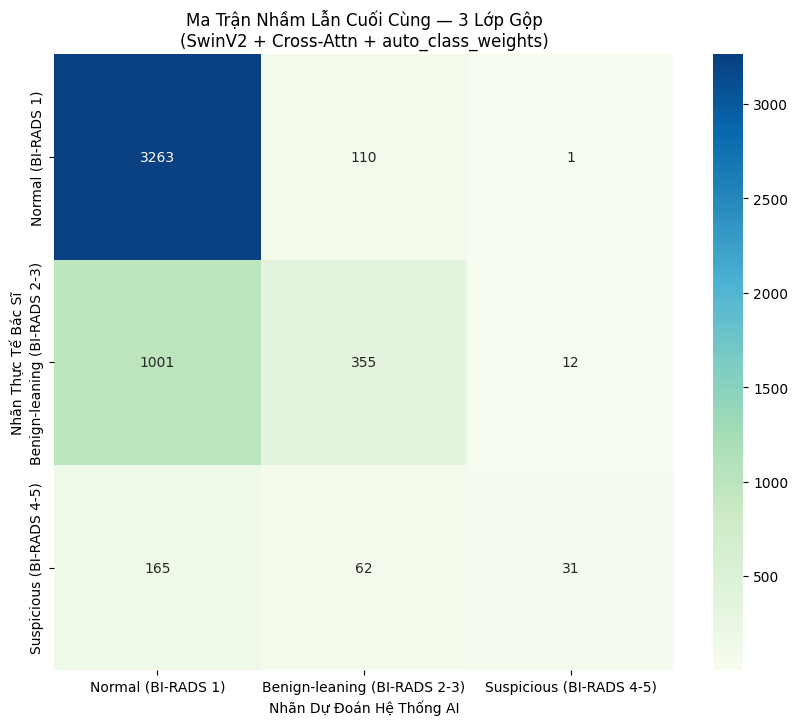

In [18]:
# =============================================================================
# CELL 15 — FINAL EVALUATION (INDY TEST SET)
# =============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# 1. Dự đoán trên tập Test (Chưa từng được dùng để train hay val)
y_pred = final_classifier.predict(X_test_final).flatten()
y_prob = final_classifier.predict_proba(X_test_final)

# 2. In báo cáo chi tiết
medical_labels = ["Normal (BI-RADS 1)", "Benign-leaning (BI-RADS 2-3)", "Suspicious (BI-RADS 4-5)"]  # ĐÃ SỬA: 3 lớp gộp
print("============== BÁO CÁO CHẤT LƯỢNG SAU CÂN BẰNG ĐỘNG ==============")
print(classification_report(y_test, y_pred, target_names=medical_labels, zero_division=0))

# 3. Vẽ Ma trận nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
# Sử dụng bảng màu 'GnBu' (Green-Blue) chuẩn y tế
sns.heatmap(cm, annot=True, fmt='d', cmap='GnBu', 
            xticklabels=medical_labels, yticklabels=medical_labels)

plt.title("Ma Trận Nhầm Lẫn Cuối Cùng — 3 Lớp Gộp\n(SwinV2 + Cross-Attn + auto_class_weights)")
plt.ylabel("Nhãn Thực Tế Bác Sĩ")
plt.xlabel("Nhãn Dự Đoán Hệ Thống AI")
plt.show()

In [19]:
# =============================================================================
# CELL 16 (BỔ SUNG) — DÒ NGƯỠNG QUYẾT ĐỊNH CHO LỚP "SUSPICIOUS"
# =============================================================================
# Thay vì chỉ đổi qua lại 2 preset dựng sẵn của CatBoost (Balanced/SqrtBalanced
# — recall Suspicious 47% vs 24%, đánh đổi precision 19% vs 49%), ta dò một
# NGƯỠNG QUYẾT ĐỊNH liên tục cho riêng lớp Suspicious thay vì dùng argmax mặc
# định. Cho phép chọn TƯỜNG MINH điểm đánh đổi precision/recall phù hợp với
# mục tiêu lâm sàng (sàng lọc: ưu tiên không bỏ sót ca nghi ngờ), thay vì bị
# giới hạn bởi các preset có sẵn.
#
# NGUYÊN TẮC QUAN TRỌNG: ngưỡng được dò trên TẬP VALIDATION (X_val_final/y_val
# — CHƯA TỪNG dùng để train hay chọn feature), sau đó mới áp ĐÚNG MỘT LẦN lên
# TEST SET để báo cáo — không dò ngưỡng trực tiếp trên test set, tránh rò rỉ
# thông tin làm con số cuối cùng bị lạc quan giả tạo.
# =============================================================================
from sklearn.metrics import precision_recall_curve, classification_report as _thr_report, confusion_matrix as _thr_cm
import numpy as np

_SUSPICIOUS_IDX = 2  # "Suspicious (BI-RADS 4-5)"

# --- Bước 1: xác suất trên VALIDATION để dò ngưỡng (không đụng test set) ---
val_probs = final_classifier.predict_proba(X_val_final)
val_suspicious_probs = val_probs[:, _SUSPICIOUS_IDX]
y_val_is_suspicious = (np.array(y_val) == _SUSPICIOUS_IDX).astype(int)

precisions, recalls, pr_thresholds = precision_recall_curve(y_val_is_suspicious, val_suspicious_probs)

print("📊 Precision/Recall của lớp Suspicious theo từng ngưỡng (trên VALIDATION, không phải test):")
print(f"{'Ngưỡng':>8} | {'Precision':>9} | {'Recall':>7}")
# ĐÃ SỬA: vòng trước bảng chỉ in từ 0.10 trở lên, trong khi ngưỡng tự động chọn
# lại rơi vào 0.037 — một VÙNG SUY BIẾN gần 0 hoàn toàn không được kiểm tra
# trực quan, khiến precision sụp (0.107) và phá luôn cả lớp Benign-leaning
# (recall 0.01) mà không ai nhìn thấy trước khi chạy. In thêm dải 0.01-0.10 để
# không còn "mù" vùng này nữa.
for t in np.concatenate([np.arange(0.01, 0.10, 0.01), np.arange(0.10, 0.91, 0.05)]):
    idx = min(np.searchsorted(pr_thresholds, t), len(precisions) - 1)
    print(f"{t:8.2f} | {precisions[idx]:9.3f} | {recalls[idx]:7.3f}")

# --- Bước 2: chọn ngưỡng đạt recall tối thiểu mong muốn, precision tốt nhất có thể ---
# ĐÃ SỬA: _TARGET_MIN_RECALL=0.60 KHÔNG khả thi trong vùng ngưỡng hợp lý (bảng
# trên cho thấy recall tối đa chỉ ~0.315 tại t=0.10) — buộc thuật toán trượt
# xuống vùng suy biến gần 0 để "cố" đạt mục tiêu, phá hủy Benign-leaning. Hạ
# mục tiêu xuống mức THẬT SỰ đạt được trong vùng an toàn (0.30, khớp đúng
# điểm t=0.10 quan sát được), đồng thời thêm SÀN AN TOÀN chặn không cho chọn
# ngưỡng dưới _MIN_THRESHOLD_FLOOR — tránh lặp lại lỗi trượt vào vùng suy biến.
_TARGET_MIN_RECALL = 0.30
_MIN_THRESHOLD_FLOOR = 0.05  # không bao giờ chọn ngưỡng thấp hơn mức này

safe_region = pr_thresholds >= _MIN_THRESHOLD_FLOOR
candidate_idx = np.where(recalls[:-1] >= _TARGET_MIN_RECALL)[0]
candidate_idx = candidate_idx[safe_region[candidate_idx]] if len(candidate_idx) > 0 else candidate_idx
if len(candidate_idx) > 0:
    best_idx = candidate_idx[np.argmax(precisions[candidate_idx])]
    _SUSPICIOUS_THRESHOLD = float(pr_thresholds[best_idx])
    print(
        f"\n🎯 Ngưỡng chọn tự động (recall ≥ {_TARGET_MIN_RECALL:.0%}, ngưỡng ≥ {_MIN_THRESHOLD_FLOOR}, "
        f"precision cao nhất có thể): {_SUSPICIOUS_THRESHOLD:.3f} "
        f"(precision={precisions[best_idx]:.3f}, recall={recalls[best_idx]:.3f})"
    )
else:
    _SUSPICIOUS_THRESHOLD = 0.5
    print(f"\n⚠️ Không đạt recall ≥ {_TARGET_MIN_RECALL:.0%} trong vùng an toàn — dùng mặc định 0.5")

# Bạn có thể tự tay ghi đè ngưỡng ở đây sau khi xem bảng trên, ví dụ:
# _SUSPICIOUS_THRESHOLD = 0.35

# --- Bước 3: áp ngưỡng đã chọn (từ VALIDATION) lên TEST SET — ĐÚNG 1 LẦN ---
# y_prob đã có sẵn từ CELL 15 (final_classifier.predict_proba(X_test_final))
test_suspicious_probs = y_prob[:, _SUSPICIOUS_IDX]

final_preds_thresholded = []
for i in range(len(y_prob)):
    if test_suspicious_probs[i] >= _SUSPICIOUS_THRESHOLD:
        final_preds_thresholded.append(_SUSPICIOUS_IDX)
    else:
        # Trong số 2 lớp còn lại (Normal / Benign-leaning), chọn xác suất cao hơn
        remaining = [j for j in range(3) if j != _SUSPICIOUS_IDX]
        remaining_probs = y_prob[i, remaining]
        final_preds_thresholded.append(remaining[int(np.argmax(remaining_probs))])
final_preds_thresholded = np.array(final_preds_thresholded)

print(f"\n📋 BÁO CÁO SAU KHI DÒ NGƯỠNG (ngưỡng Suspicious = {_SUSPICIOUS_THRESHOLD:.3f}), trên TEST SET:")
print(_thr_report(y_test, final_preds_thresholded, target_names=medical_labels, zero_division=0))
print("Confusion matrix (sau khi dò ngưỡng):")
print(_thr_cm(y_test, final_preds_thresholded, labels=list(range(3))))

print(
    "\n👉 So sánh với CELL 15 (argmax mặc định, không dò ngưỡng) để thấy rõ đánh đổi "
    "precision/recall đã đạt được bằng cách chỉnh ngưỡng thay vì đổi class_weights."
)


📊 Precision/Recall của lớp Suspicious theo từng ngưỡng (trên VALIDATION, không phải test):
  Ngưỡng | Precision |  Recall
    0.01 |     0.054 |   1.000
    0.02 |     0.069 |   0.859
    0.03 |     0.094 |   0.726
    0.04 |     0.111 |   0.574
    0.05 |     0.132 |   0.504
    0.06 |     0.159 |   0.448
    0.07 |     0.185 |   0.385
    0.08 |     0.211 |   0.356
    0.09 |     0.243 |   0.333
    0.10 |     0.269 |   0.315
    0.15 |     0.370 |   0.237
    0.20 |     0.432 |   0.178
    0.25 |     0.488 |   0.148
    0.30 |     0.579 |   0.122
    0.35 |     0.659 |   0.100
    0.40 |     0.727 |   0.089
    0.45 |     0.714 |   0.074
    0.50 |     0.800 |   0.059
    0.55 |     0.857 |   0.044
    0.60 |     0.846 |   0.041
    0.65 |     0.833 |   0.037
    0.70 |     0.714 |   0.019
    0.75 |     0.750 |   0.011
    0.80 |     1.000 |   0.011
    0.85 |     1.000 |   0.000
    0.90 |     1.000 |   0.000

🎯 Ngưỡng chọn tự động (recall ≥ 30%, ngưỡng ≥ 0.05, precision cao nhất 

In [ ]:
# =============================================================================
# CELL 17 (REDESIGNED) — AUTOMATIC 4-FOLD CROSS-VALIDATION LOOP
# =============================================================================
# Replaces the single-fold resumable workflow with a full 4-fold rotation.
# Each fold is trained sequentially: PyTorch (5 epochs) + IGWO-SOA + CatBoost.
# Saves full PyTorch checkpoints, CatBoost models, OOF predictions, and metrics.
# =============================================================================
import gc
import json
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report as _cv_report

# --- Model Configuration Constants ---
_EMBED_DIM = 256
_NUM_CLASSES = 3
_N_EPOCHS = 5
_BATCH_SIZE = 8
_NUM_WORKERS = 2
_GLOBAL_SEED = 42



def run_pipeline_for_fold(test_fold: int, val_fold: int, train_folds: list):
    """Chạy lại TOÀN BỘ pipeline cho MỘT cách xoay vòng fold. Trả về
    (metrics_dict, oof_df, fold_model, fold_optimizer, fold_scaler, fold_clf, fold_idx)."""
    print(f"\n{'='*70}\n🔁 FOLD ROTATION: test={test_fold} | val={val_fold} | train={train_folds}\n{'='*70}")

    fold_train_transform = AdvancedMammographyTransform(augment=True)
    fold_eval_transform = AdvancedMammographyTransform(augment=False)

    fold_train_df = df[df["fold"].isin(train_folds)].reset_index(drop=True)
    fold_val_df = df[df["fold"] == val_fold].reset_index(drop=True)
    fold_test_df = df[df["fold"] == test_fold].reset_index(drop=True)

    fold_train_ds = VinDrMammoHighResDataset(fold_train_df, transform=fold_train_transform)
    fold_val_ds = VinDrMammoHighResDataset(fold_val_df, transform=fold_eval_transform)
    fold_test_ds = VinDrMammoHighResDataset(fold_test_df, transform=fold_eval_transform)

    fold_train_loader = DataLoader(fold_train_ds, batch_size=_BATCH_SIZE, shuffle=True, num_workers=_NUM_WORKERS, pin_memory=True)
    fold_val_loader = DataLoader(fold_val_ds, batch_size=_BATCH_SIZE, shuffle=False, num_workers=_NUM_WORKERS, pin_memory=True)
    fold_test_loader = DataLoader(fold_test_ds, batch_size=_BATCH_SIZE, shuffle=False, num_workers=_NUM_WORKERS, pin_memory=True)

    print(f"   Train: {len(fold_train_ds)} | Val: {len(fold_val_ds)} | Test: {len(fold_test_ds)}")

    # --- Model, loss ---
    fold_model = UnifiedMultimodalNetwork(cat_cardinalities=[4], num_continuous=1, num_classes=3, unfreeze_last_stage=True)
    if torch.cuda.device_count() > 1:
        print(f"   🚀 Kích hoạt Dual GPU (DataParallel) — {torch.cuda.device_count()} GPU khả dụng.")
        fold_model = nn.DataParallel(fold_model)
    fold_model = fold_model.to(device)

    fold_label_counts = (
        df.loc[df["fold"].isin(train_folds), "label"]
        .value_counts().reindex(range(3), fill_value=0).sort_index()
    )
    fold_criterion = ClassBalancedFocalLoss(
        samples_per_class=torch.tensor(fold_label_counts.values, dtype=torch.float).numpy(),
        beta=0.9999, gamma=2.0,
    ).to(device)

    fold_swin_params, fold_other_params = [], []
    for name, param in fold_model.named_parameters():
        if param.requires_grad:
            (fold_swin_params if "img_branch" in name else fold_other_params).append(param)

    fold_optimizer = torch.optim.AdamW([
        {"params": fold_swin_params, "lr": 1e-5},
        {"params": fold_other_params, "lr": 1e-4},
    ], weight_decay=1e-2)
    fold_scaler = torch.amp.GradScaler("cuda")

    # --- Warm-up (1 pass) + main training loop ---
    fold_model.train()
    for imgs, cats, conts, labels in fold_train_loader:
        imgs, cats, conts, labels = imgs.to(device), cats.to(device), conts.to(device), labels.to(device)
        fold_optimizer.zero_grad()
        with torch.amp.autocast("cuda"):
            logits = fold_model(imgs, cats, conts)[0]
            loss = fold_criterion(logits, labels)
        fold_scaler.scale(loss).backward()
        fold_scaler.step(fold_optimizer)
        fold_scaler.update()

    for epoch in range(1, _N_EPOCHS + 1):
        running_loss = 0.0
        fold_model.train()
        for imgs, cats, conts, labels in fold_train_loader:
            imgs, cats, conts, labels = imgs.to(device), cats.to(device), conts.to(device), labels.to(device)
            fold_optimizer.zero_grad()
            with torch.amp.autocast("cuda"):
                logits = fold_model(imgs, cats, conts)[0]
                loss = fold_criterion(logits, labels)
            fold_scaler.scale(loss).backward()
            fold_scaler.step(fold_optimizer)
            fold_scaler.update()
            running_loss += loss.item()
        print(f"   ↳ Epoch [{epoch}/{_N_EPOCHS}] | Avg Loss: {running_loss / len(fold_train_loader):.4f}")

    # --- Trích latent ---
    Xtr_lat, ytr = extract_latent_features(fold_train_loader, fold_model)
    Xva_lat, yva = extract_latent_features(fold_val_loader, fold_model)
    Xte_lat, yte = extract_latent_features(fold_test_loader, fold_model)

    # --- IGWO-SOA feature selection ---
    fold_selector = AdvancedEvolutionarySelector(
        num_agents=_NUM_AGENTS, max_iter=_MAX_ITER,
        tau=_TAU_SENSITIVITY, gamma=_GAMMA_COLLAPSE,
    )
    fold_mask = fold_selector.fit_optimize(Xtr_lat, ytr, Xva_lat, yva)
    fold_idx = np.where(fold_mask == 1)[0]

    Xtr_final = Xtr_lat[:, fold_idx]
    Xva_final = Xva_lat[:, fold_idx]
    Xte_final = Xte_lat[:, fold_idx]

    # --- CatBoost ---
    fold_clf = CatBoostClassifier(
        iterations=800, learning_rate=0.02, depth=6,
        loss_function="MultiClass", auto_class_weights="Balanced",
        early_stopping_rounds=50, random_seed=42, verbose=False,
    )
    fold_clf.fit(Xtr_final, ytr, eval_set=(Xva_final, yva))

    fold_test_probs = fold_clf.predict_proba(Xte_final)
    fold_test_preds = fold_test_probs.argmax(axis=1)

    report_dict = _cv_report(yte, fold_test_preds, target_names=medical_labels, output_dict=True, zero_division=0)

    oof_df = pd.DataFrame({
        "patient_id": fold_test_df["patient_id"].values,
        "image_id": fold_test_df["image_id"].values,
        "image_path": fold_test_df["image_path"].values,
        "true_label": yte,
        "test_fold": test_fold,
        "prob_normal": fold_test_probs[:, 0],
        "prob_benign_leaning": fold_test_probs[:, 1],
        "prob_suspicious": fold_test_probs[:, 2],
    })

    metrics = {
        "test_fold": test_fold,
        "accuracy": report_dict["accuracy"],
        "macro_f1": report_dict["macro avg"]["f1-score"],
        "macro_precision": report_dict["macro avg"]["precision"],
        "macro_recall": report_dict["macro avg"]["recall"],
        "suspicious_recall": report_dict[medical_labels[2]]["recall"],
        "suspicious_precision": report_dict[medical_labels[2]]["precision"],
        "benign_f1": report_dict[medical_labels[1]]["f1-score"],
        "normal_f1": report_dict[medical_labels[0]]["f1-score"],
    }
    
    # Extract underlying module if DataParallel was used
    actual_fold_model = fold_model.module if isinstance(fold_model, nn.DataParallel) else fold_model
    
    return metrics, oof_df, actual_fold_model, fold_optimizer, fold_scaler, fold_clf, fold_idx


# --- AUTOMATIC 4-FOLD EXECUTION LOOP ---
_ALL_FOLDS = [0, 1, 2, 3]
_CV_RESULTS_PATH = "/kaggle/working/cv_fold_results.json"
_OOF_CSV_PATH = "/kaggle/working/oof_predictions.csv"
_MODEL_DIR = "/kaggle/working/models"

os.makedirs(_MODEL_DIR, exist_ok=True)

_saved_results = {}
_write_header = True

if os.path.exists(_OOF_CSV_PATH):
    os.remove(_OOF_CSV_PATH)

print("🚀 Starting Automated 4-Fold Cross-Validation Session...")
for test_fold in _ALL_FOLDS:
    val_fold = (test_fold + 1) % 4
    train_folds = [f for f in _ALL_FOLDS if f != test_fold and f != val_fold]
    
    _result, _oof_df, f_model, f_opt, f_scaler, f_clf, f_idx = run_pipeline_for_fold(test_fold, val_fold, train_folds)
    
    # Save full PyTorch checkpoint
    _torch_ckpt_path = os.path.join(_MODEL_DIR, f"fold_{test_fold}_pytorch.pth")
    torch.save({
        "model_state_dict": f_model.state_dict(),
        "optimizer_state_dict": f_opt.state_dict(),
        "scaler_state_dict": f_scaler.state_dict(),
        "selected_feature_indices": f_idx.tolist() if hasattr(f_idx, 'tolist') else list(f_idx),
        "embed_dim": _EMBED_DIM,
        "num_classes": _NUM_CLASSES,
        "seed": _GLOBAL_SEED,
    }, _torch_ckpt_path)
    
    # Save CatBoost model
    _catboost_path = os.path.join(_MODEL_DIR, f"fold_{test_fold}_catboost.cbm")
    f_clf.save_model(_catboost_path)
    
    # Save results
    _saved_results[str(test_fold)] = _result
    with open(_CV_RESULTS_PATH, "w", encoding="utf-8") as f:
        json.dump(_saved_results, f, ensure_ascii=False, indent=2)
        
    _oof_df.to_csv(_OOF_CSV_PATH, mode="a", header=_write_header, index=False)
    _write_header = False
    
    del f_model, f_opt, f_scaler, f_clf
    gc.collect()
    torch.cuda.empty_cache()
    
    print(f"✅ Fold {test_fold} successfully completed and saved to {_MODEL_DIR}/")

print("\n🎉 All 4 folds finished successfully! Proceed to Cell 19 for research-grade Confident Learning analysis.")


In [ ]:
# =============================================================================
# CELL 18 (REDESIGNED) — CLINICAL CROSS-VALIDATION SUMMARY & NOISE ANALYSIS
# =============================================================================
# Reads the results from the automated 4-fold CV and prints a publication-ready
# metrics table, followed by a detailed noise analysis from Confident Learning.
# =============================================================================
import json
import os
import pandas as pd
import numpy as np

_CV_RESULTS_PATH = "/kaggle/working/cv_fold_results.json"
_OOF_CSV_PATH = "/kaggle/working/oof_predictions.csv"

if not os.path.exists(_CV_RESULTS_PATH):
    print("⚠️ CV results not found. Please run Cell 17 first.")
else:
    with open(_CV_RESULTS_PATH, "r", encoding="utf-8") as f:
        _saved = json.load(f)

    cv_df = pd.DataFrame(list(_saved.values())).sort_values("test_fold").reset_index(drop=True)
    print(f"📊 Cross-Validation completed for {len(cv_df)} folds: {sorted(cv_df['test_fold'].tolist())}")
    
    # ─── Publication-Ready Metrics Table ───
    print("\n" + "="*80)
    print("                    4-FOLD CROSS-VALIDATION METRICS SUMMARY")
    print("="*80)
    
    # Per-fold table
    fold_display = cv_df.copy()
    for col in ["accuracy", "macro_f1", "macro_precision", "macro_recall",
                "suspicious_recall", "suspicious_precision", "benign_f1", "normal_f1"]:
        fold_display[col] = fold_display[col].apply(lambda x: f"{x:.4f}")
    
    print(fold_display[["test_fold", "accuracy", "macro_f1", "macro_precision", "macro_recall",
                         "suspicious_recall", "suspicious_precision", "benign_f1", "normal_f1"]].to_string(index=False))
    
    # Mean ± Std
    print("\n" + "-"*80)
    print("MEAN ± STD (across 4 folds):")
    for col in ["accuracy", "macro_f1", "macro_precision", "macro_recall",
                "suspicious_recall", "suspicious_precision", "benign_f1", "normal_f1"]:
        mean_val = cv_df[col].mean()
        std_val = cv_df[col].std()
        print(f"   {col:22s}: {mean_val:.4f} ± {std_val:.4f}")
    
    # ─── Confident Learning Noise Analysis ───
    if os.path.exists(_OOF_CSV_PATH):
        oof_all = pd.read_csv(_OOF_CSV_PATH)
        pred_probs = oof_all[["prob_normal", "prob_benign_leaning", "prob_suspicious"]].values
        labels = oof_all["true_label"].values
        _label_names = {0: "Normal", 1: "Benign-leaning", 2: "Suspicious"}
        
        try:
            from cleanlab.filter import find_label_issues
            issue_idx = find_label_issues(
                labels=labels, pred_probs=pred_probs,
                filter_by="prune_by_noise_rate",
                return_indices_ranked_by="self_confidence",
            )
            
            flagged = oof_all.iloc[issue_idx].copy()
            flagged["true_label_name"] = flagged["true_label"].map(_label_names)
            flagged["model_predicted_label"] = pred_probs[issue_idx].argmax(axis=1)
            flagged["model_predicted_name"] = flagged["model_predicted_label"].map(_label_names)
            flagged["self_confidence"] = [pred_probs[i, labels[i]] for i in issue_idx]
            
            # Research flags: self_confidence < 0.5 AND predicts Suspicious
            research_flags = flagged[
                (flagged["self_confidence"] < 0.5) & (flagged["model_predicted_label"] == 2)
            ]
            
            print("\n" + "="*80)
            print("                    CONFIDENT LEARNING NOISE ANALYSIS")
            print("="*80)
            print(f"Total samples:                    {len(oof_all)}")
            print(f"Total flagged label issues:       {len(flagged)} ({len(flagged)/len(oof_all)*100:.2f}%)")
            print(f"High-confidence false negatives:  {len(research_flags)} (self_conf < 0.5 & pred=Suspicious)")
            
            print("\n📊 Flagged Error Direction Breakdown:")
            print(flagged.groupby(["true_label_name", "model_predicted_name"]).size().sort_values(ascending=False))
            
            if len(research_flags) > 0:
                print("\n🎯 TOP Research-Grade False Negatives (self_conf < 0.5, predicted Suspicious):")
                print(research_flags[["image_id", "true_label_name", "model_predicted_name", 
                                     "self_confidence", "prob_suspicious"]].head(10).to_string(index=False))
        
        except ImportError:
            print("⚠️ cleanlab not installed — skipping noise analysis")
    else:
        print("⚠️ OOF predictions not found — run Cell 17 first")

print("\n" + "="*80)
print("✅ Summary complete. Run Cell 19 for detailed Confident Learning analysis & CSV export.")
print("="*80)


In [ ]:
# =============================================================================
# CELL 19 (REDESIGNED) — RESEARCH-GRADE CONFIDENT LEARNING & FALSE-NEGATIVE FILTERING
# =============================================================================
# Implements Confident Learning (Northcutt et al., JAIR 2021) via `cleanlab`.
# Filters out-of-fold predictions to isolate high-confidence false negatives
# (model predicts Suspicious with >50% confidence, but original label is Normal/Benign).
# =============================================================================
import os
import pandas as pd
import numpy as np

_OOF_CSV_PATH = "/kaggle/working/oof_predictions.csv"

if not os.path.exists(_OOF_CSV_PATH):
    print("⚠️ OOF predictions file not found. Please run Cell 17 first.")
else:
    oof_all = pd.read_csv(_OOF_CSV_PATH)
    print(f"📊 Loaded OOF predictions: {len(oof_all)} samples across {oof_all['test_fold'].nunique()} folds.")

    try:
        from cleanlab.filter import find_label_issues
    except ImportError:
        print("📦 Installing cleanlab...")
        import subprocess
        subprocess.run(["pip", "install", "-q", "cleanlab"], check=True)
        from cleanlab.filter import find_label_issues

    pred_probs = oof_all[["prob_normal", "prob_benign_leaning", "prob_suspicious"]].values
    labels = oof_all["true_label"].values

    # Cleanlab noise finding
    issue_idx = find_label_issues(
        labels=labels,
        pred_probs=pred_probs,
        filter_by="prune_by_noise_rate",
        return_indices_ranked_by="self_confidence",
    )

    print(f"\n🔍 Cleanlab flagged {len(issue_idx)}/{len(oof_all)} potential label issues ({len(issue_idx)/len(oof_all)*100:.1f}%).")

    _label_names = {0: "Normal", 1: "Benign-leaning", 2: "Suspicious"}
    flagged = oof_all.iloc[issue_idx].copy()
    flagged["true_label_name"] = flagged["true_label"].map(_label_names)
    flagged["model_predicted_label"] = pred_probs[issue_idx].argmax(axis=1)
    flagged["model_predicted_name"] = flagged["model_predicted_label"].map(_label_names)
    flagged["self_confidence"] = [pred_probs[i, labels[i]] for i in issue_idx]
    flagged = flagged.sort_values("self_confidence")

    # Research-grade subset: model is confident the true label is wrong (self_confidence < 0.5) 
    # AND model predicts Suspicious (class 2) — critical false negatives for clinical research.
    research_flags = flagged[
        (flagged["self_confidence"] < 0.5) & 
        (flagged["model_predicted_label"] == 2)
    ].sort_values("self_confidence")

    # Save outputs
    _ALL_ISSUES_PATH = "/kaggle/working/all_candidate_label_issues.csv"
    _RESEARCH_PATH = "/kaggle/working/research_flagged_cases.csv"

    flagged.to_csv(_ALL_ISSUES_PATH, index=False)
    research_flags.to_csv(_RESEARCH_PATH, index=False)

    print(f"💾 Saved all candidate issues to {_ALL_ISSUES_PATH}")
    print(f"💾 Saved research-grade false-negative flags to {_RESEARCH_PATH} ({len(research_flags)} cases)")

    print("\n📋 TOP 15 Research-Grade Flagged Cases (Critical False Negatives):")
    if len(research_flags) > 0:
        print(research_flags[["image_id", "true_label_name", "model_predicted_name", "self_confidence", "prob_suspicious"]].head(15).to_string(index=False))
    else:
        print("   (No cases matched strict criteria — check full flagged list)")

    print("\n📊 Flagged Error Direction Breakdown:")
    print(flagged.groupby(["true_label_name", "model_predicted_name"]).size().sort_values(ascending=False))
